# GMRT 海底正断层自动识别 · 实现笔记本

从**下载 GMRT** 一路做到**断层识别结果**。本文件完全独立：不读取开发笔记本的任何文件。

第 5 步中的核心参数，是研究员先运行开发笔记本 `GMRT_fault_development.ipynb`，再把它最后打印出的数值**手动抄写**过来的。
换数据区域时，应先用开发笔记本重新研究，再把新数值抄到第 5 步。

代码不定义任何函数或类，按步骤从上到下依次执行：

| 步骤 | 内容 |
|---|---|
| 0 | 配置与导入 |
| 1–4 | 前置部分：下载 GMRT（`topo` 和 `topo-mask`）→ 读取 → 重投影到 UTM → 数据调理 |
| 5 | 核心参数（由开发笔记本得出，手动输入） |
| 6–13 | 核心部分：地形导数 → 陡坎候选 → 断距 → 骨架 → 路径 → 分段 → 连接 → 特征 |
| 14 | 接受规则和学习得到的评分器 |
| 15 | 中轴与内倾/外倾 |
| 16 | 构造应变 |
| 17 | 输出 GeoJSON/CSV 与图 |

## 0. 配置与导入

In [1]:
AOI_NAME = "mar29n"                          # 区域名
BBOX = (-43.75, -42.55, 28.74, 29.36)        # (west, east, south, north)，十进制度
GMRT_RES = "max"                              # GMRT 分辨率：default / med / high / max
RAW_DIR = f"data/gmrt/{AOI_NAME}"             # GMRT 下载目录
OUT_DIR = f"nb_output/{AOI_NAME}"             # 结果输出目录

In [2]:
import csv
import json
import os
import shutil
import time
import urllib.parse
import urllib.request

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy import ndimage as ndi
from scipy.signal import oaconvolve
from scipy.spatial import cKDTree
from scipy.stats import theilslopes
from skimage.filters import apply_hysteresis_threshold
from skimage.morphology import skeletonize
import tifffile
from pyproj import Transformer

%config InlineBackend.figure_formats = ["jpeg"]
plt.rcParams["figure.dpi"] = 80
os.makedirs(RAW_DIR, exist_ok=True)
print("numpy", np.__version__, "| tifffile", tifffile.__version__)
os.makedirs(OUT_DIR, exist_ok=True)

numpy 2.5.3 | tifffile 2026.10.15


---
# 前置部分
## 1. 下载 GMRT

GMRT GridServer 返回 GeoTIFF。`topo` 图层中，测线之间的空隙用 GEBCO 填补；`topo-mask` 图层只保留高分辨率多波束数据，其余为 NaN。两个图层都要下载。

In [3]:
GRIDSERVER = "https://www.gmrt.org/services/GridServer"
west, east, south, north = BBOX
gmrt_files = {}
for layer in ("topo", "topo-mask"):
    out_path = os.path.join(RAW_DIR, f"gmrt_{layer}.tif")
    gmrt_files[layer] = out_path
    if os.path.exists(out_path) and os.path.getsize(out_path) > 0:
        print(f"{out_path} 已存在，跳过下载")
        continue
    query = urllib.parse.urlencode({"west": f"{west:.6f}", "east": f"{east:.6f}", "south": f"{south:.6f}",
                                    "north": f"{north:.6f}", "layer": layer, "format": "geotiff",
                                    "resolution": GMRT_RES})
    url = f"{GRIDSERVER}?{query}"
    for attempt in range(4):
        try:
            with urllib.request.urlopen(url, timeout=900) as resp, open(out_path + ".part", "wb") as fh:
                shutil.copyfileobj(resp, fh, length=1 << 20)
            if os.path.getsize(out_path + ".part") < 1024:
                raise RuntimeError("GridServer 没有返回网格")
            os.replace(out_path + ".part", out_path)
            print(f"已下载 {layer}: {os.path.getsize(out_path) / 1e6:.1f} MB")
            break
        except Exception as exc:
            print(f"{layer} 第 {attempt + 1} 次下载失败: {exc}")
            time.sleep(2 ** (attempt + 1))
    else:
        raise RuntimeError(f"无法下载 {url}")

data/gmrt/mar29n/gmrt_topo.tif 已存在，跳过下载
data/gmrt/mar29n/gmrt_topo-mask.tif 已存在，跳过下载


## 2. 读取 GeoTIFF 与地理参考

In [4]:
layers = {}
for layer, path in gmrt_files.items():
    with tifffile.TiffFile(path) as tif:
        page = tif.pages[0]
        scale = page.tags["ModelPixelScaleTag"].value
        tie = page.tags["ModelTiepointTag"].value
        gk = page.tags["GeoKeyDirectoryTag"].value
        layers[layer] = page.asarray().astype(np.float32)
    geokeys = {gk[k]: gk[k + 3] for k in range(4, len(gk), 4) if gk[k + 1] == 0}
    assert geokeys.get(1024) == 2 and geokeys.get(2048) == 4326, "GMRT 应返回 WGS84 经纬度网格"
    half = 0.5 if geokeys.get(1025, 1) == 1 else 0.0          # PixelIsArea: 连接点在像元角上
    DLON, DLAT = float(scale[0]), float(scale[1])
    LON0 = float(tie[3]) + (half - float(tie[0])) * DLON      # 像元 [0,0] 中心的经度
    LAT0 = float(tie[4]) - (half - float(tie[1])) * DLAT      # 像元 [0,0] 中心的纬度
topo = layers["topo"]
valid_src = np.isfinite(topo) & np.isfinite(layers["topo-mask"])   # topo-mask 有值 = 多波束数据
NY_SRC, NX_SRC = topo.shape
print(f"GMRT 网格 {NX_SRC} x {NY_SRC} 节点，间距 {DLON:.6f}° x {DLAT:.6f}°；多波束数据占 {valid_src.mean():.1%}")

GMRT 网格 2186 x 1294 节点，间距 0.000550° x 0.000481°；多波束数据占 88.5%


## 3. 从经纬度重投影到 UTM 米制网格

In [5]:
lat_c = LAT0 - 0.5 * (NY_SRC - 1) * DLAT
lon_c = LON0 + 0.5 * (NX_SRC - 1) * DLON
zone = int(np.floor((lon_c + 180.0) / 6.0)) % 60 + 1
EPSG = (32600 if lat_c >= 0 else 32700) + zone
deg_m = np.pi / 180.0 * 6378137.0
native_m = min(DLON * deg_m * np.cos(np.radians(lat_c)), DLAT * deg_m)
PX = float(max(5.0, 5.0 * np.floor(native_m / 5.0)))     # 原生地面间距向下取整到 5 m
to_utm = Transformer.from_crs("EPSG:4326", f"EPSG:{EPSG}", always_xy=True)
to_geo = Transformer.from_crs(f"EPSG:{EPSG}", "EPSG:4326", always_xy=True)

# 目标网格范围：把源网格四条边投影过去，取内接范围
lon_axis = LON0 + np.arange(NX_SRC) * DLON
lat_axis = LAT0 - np.arange(NY_SRC) * DLAT
b_lon = np.concatenate([lon_axis, np.full(NY_SRC, lon_axis[-1]), lon_axis[::-1], np.full(NY_SRC, lon_axis[0])])
b_lat = np.concatenate([np.full(NX_SRC, lat_axis[0]), lat_axis, np.full(NX_SRC, lat_axis[-1]), lat_axis[::-1]])
bx, by = to_utm.transform(b_lon, b_lat)
x_min, x_max = np.ceil(np.min(bx) / PX) * PX, np.floor(np.max(bx) / PX) * PX
y_min, y_max = np.ceil(np.min(by) / PX) * PX, np.floor(np.max(by) / PX) * PX
NX = int(round((x_max - x_min) / PX)) + 1
NY = int(round((y_max - y_min) / PX)) + 1
X0, Y0 = float(x_min), float(y_max)                         # 目标像元 [0,0] 的中心（西北角）

# 逆映射 + 双线性插值；只要有一个参与插值的源节点无效，目标像元就无效
_, (ri_src, ci_src) = ndi.distance_transform_edt(~valid_src, return_indices=True)
z_src = topo[ri_src, ci_src].astype(np.float64)
v_src = valid_src.astype(np.float64)
dem_proj = np.full((NY, NX), np.nan, np.float32)
xs_axis = X0 + np.arange(NX) * PX
for r0 in range(0, NY, 512):
    r1 = min(NY, r0 + 512)
    XX, YY = np.meshgrid(xs_axis, Y0 - np.arange(r0, r1) * PX)
    LON, LAT = to_geo.transform(XX, YY)
    src_r = ((LAT0 - LAT) / DLAT).ravel()
    src_c = ((LON - LON0) / DLON).ravel()
    zz = ndi.map_coordinates(z_src, [src_r, src_c], order=1, mode="nearest")
    vv = ndi.map_coordinates(v_src, [src_r, src_c], order=1, mode="constant", cval=0.0)
    inside = (src_r >= 0) & (src_r <= NY_SRC - 1) & (src_c >= 0) & (src_c <= NX_SRC - 1)
    dem_proj[r0:r1] = np.where(inside & (vv >= 0.999), zz, np.nan).reshape(r1 - r0, NX).astype(np.float32)
print(f"重投影到 EPSG:{EPSG}，{PX:.0f} m 网格 {NX} x {NY}（原生约 {native_m:.1f} m）")

重投影到 EPSG:32623，50 m 网格 2360 x 1414（原生约 53.5 m）


## 4. 数据调理：去孤立块、去尖峰、补小洞

去掉 2 个孤立块、9550 个尖峰，补了 5211 个像元；有效像元 84.7%


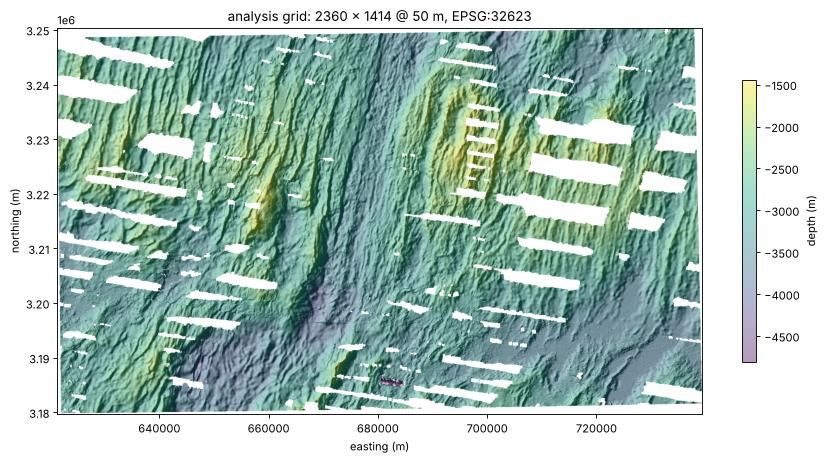

In [6]:
MIN_ISLAND_KM2 = 1.0       # 小于此面积的孤立数据块删除
DESPIKE_WINDOW_M = 250.0   # 滑动中值窗口
DESPIKE_K = 6.0            # |z - 中值| > K 倍稳健 sigma ...
DESPIKE_MIN_M = 25.0       # ... 且 > 25 m 视为尖峰
MAX_HOLE_KM2 = 0.05        # 小于此面积的空洞插值补上

z_c = dem_proj.astype(np.float64)
valid_c = np.isfinite(z_c)
px_km2 = PX * PX / 1e6
# 1) 孤立小数据块
lab, n_lab = ndi.label(valid_c, structure=np.ones((3, 3)))
sizes = ndi.sum(valid_c, lab, np.arange(1, n_lab + 1)) * px_km2
small = np.zeros(n_lab + 1, bool)
small[1:] = sizes < MIN_ISLAND_KM2
valid_c &= ~small[lab]
n_islands = int(small.sum())
# 2) 去尖峰
win = max(3, int(round(DESPIKE_WINDOW_M / PX)) | 1)
_, (ri_c, ci_c) = ndi.distance_transform_edt(~valid_c, return_indices=True)
med = ndi.median_filter(z_c[ri_c, ci_c], size=win)
resid = (z_c - med)[valid_c]
robust_sigma = 1.4826 * np.median(np.abs(resid - np.median(resid)))
spikes = valid_c & (np.abs(z_c - med) > max(DESPIKE_K * robust_sigma, DESPIKE_MIN_M))
valid_c &= ~spikes
# 3) 补小洞（不碰边界的 NaN 连通块），由小到大的高斯尺度做考虑空洞的插值
lab, n_lab = ndi.label(~valid_c, structure=np.ones((3, 3)))
sizes = ndi.sum(~valid_c, lab, np.arange(1, n_lab + 1)) * px_km2
border = np.unique(np.concatenate([lab[0], lab[-1], lab[:, 0], lab[:, -1]]))
small = np.zeros(n_lab + 1, bool)
small[1:] = sizes < MAX_HOLE_KM2
small[border] = False
holes = small[lab]
z_filled = np.where(valid_c, z_c, 0.0)
todo = holes.copy()
for sig in (1.0, 2.0, 4.0, 8.0, 16.0):
    num = ndi.gaussian_filter(np.where(valid_c, z_c, 0.0), sig)
    den = ndi.gaussian_filter(valid_c.astype(float), sig)
    ok = todo & (den > 0.05)
    z_filled[ok] = num[ok] / den[ok]
    todo &= ~ok
    if not todo.any():
        break
filled = holes & ~todo
valid_c |= filled
DEM = np.where(valid_c, z_filled, np.nan).astype(np.float32)
EXTENT = (X0 - PX / 2, X0 + (NX - 0.5) * PX, Y0 - (NY - 0.5) * PX, Y0 + PX / 2)
print(f"去掉 {n_islands} 个孤立块、{int(spikes.sum())} 个尖峰，补了 {int(filled.sum())} 个像元；有效像元 {np.isfinite(DEM).mean():.1%}")

# 山体阴影（只用于显示）
_, (ri_h, ci_h) = ndi.distance_transform_edt(~np.isfinite(DEM), return_indices=True)
d_row, d_col = np.gradient(DEM[ri_h, ci_h].astype(np.float64))
hx, hy = 2.0 * d_col / PX, -2.0 * d_row / PX
az_l, alt_l = np.radians(300.0), np.radians(40.0)
HILLSHADE = np.clip((-hx * np.sin(az_l) * np.cos(alt_l) - hy * np.cos(az_l) * np.cos(alt_l) + np.sin(alt_l))
                    / np.sqrt(1 + hx ** 2 + hy ** 2), 0, 1)
HILLSHADE[~np.isfinite(DEM)] = np.nan
fig, ax = plt.subplots(figsize=(13, 13 * NY / NX * 0.85 + 1))
ax.imshow(HILLSHADE, cmap="gray", extent=EXTENT)
im = ax.imshow(DEM, cmap="viridis", alpha=0.4, extent=EXTENT)
fig.colorbar(im, ax=ax, shrink=0.6, label="depth (m)")
ax.set_title(f"analysis grid: {NX} x {NY} @ {PX:.0f} m, EPSG:{EPSG}")
ax.set_xlabel("easting (m)")
ax.set_ylabel("northing (m)")
plt.show()

---
# 核心部分
## 5. 核心参数（由开发笔记本得出，手动抄写）

下面带"开发笔记本"注释的数值，都是从开发笔记本第 14 步打印的结果抄来的。
其余是算法的固定常数，不随数据集标定。

In [7]:
# ===================== 由开发笔记本得出，研究员手动抄写 =====================
# （来源：GMRT_fault_development.ipynb 第 14 步打印的参数，数据集 GMRT MAR 29°N）

# 开发笔记本 · 步骤 6：尺度选择（脊线坡度双峰程度 Ashman D 最大）
SIGMA_M = 75.0
# 开发笔记本 · 步骤 5：纹理方向统计（80% 权重半宽，限制在 20–45°）
ORIENT_TOL_DEG = 45.0
# 开发笔记本 · 步骤 7：坡度双高斯混合的后验
SLOPE_HIGH_DEG = 12.35
SLOPE_LOW_DEG = 8.82
STOP_SLOPE_DEG = 6.82
# 开发笔记本 · 步骤 7：随网格换算的设置
EDGE_BUFFER_M = 150.0
SIMPLIFY_TOL_M = 30.0
MIN_CANDIDATE_M = 300.0
# 开发笔记本 · 步骤 12–13：target-decoy 逻辑回归评分器（估计 FDR = 0.10）
MIN_LENGTH_M = 500.0
MIN_THROW_M = 0.0
MAX_STRIKE_DEV_DEG = 90.0
USE_SCORER = True
SCORER_FEATURES = ['log10_length_m', 'log10_throw_m', 'throw_iqr_rel', 'scarp_slope_deg', 'peak_slope_deg',
                   'log10_width_m', 'straightness', 'strike_dev_deg', 'facing_consistency']
SCORER_MEAN = [2.97665, 2.14311, 0.409322, 15.6107, 20.5966, 2.70688, 0.939218, 16.3156, 0.962246]
SCORER_SCALE = [0.210443, 0.21825, 0.277425, 3.5875, 5.19331, 0.144503, 0.0490594, 12.1769, 0.0286938]
SCORER_COEF = [0.583723, -5.04096, -0.246409, 2.56599, -0.540208, 3.39513, 0.184188, -0.317642, 0.358989]
SCORER_INTERCEPT = -0.217409
SCORER_THRESHOLD = 0.736845
# 备选（开发笔记本 · 步骤 10，统计 FDR 控制，更保守）：
# MIN_LENGTH_M = 3250.0; MIN_THROW_M = 10.0; MAX_STRIKE_DEV_DEG = 45.0; USE_SCORER = False
# 开发笔记本 · 步骤 15：外倾陡坎与 TOBI 侧扫的一致度和随机水平相当（大多不是断层）-> 只保留内倾
KEEP_OUTWARD = False

# ===================== 算法固定常数（不随数据集标定）=====================
STRIKE_FIXED = None          # None = 用结构张量自动估计区域走向
REL_STOP = 0.25              # 坡度 < 0.25 × 峰值坡度时视为到达坡折
RISE_TOL_DEG = 2.0           # 坡度回升超过 2° 视为进入下一条陡坎
MAX_WALK_M = 2000.0          # 沿倾向最远走 2 km
MIN_PIXEL_THROW_M = 20.0     # 单个中心线像元的断距至少 20 m
LINK_GAP_M = 500.0           # 连接共线线段的最大间隙
LINK_ANGLE_DEG = 25.0        # 连接时允许的最大方向变化

## 6. 地形导数与区域走向

In [8]:
Z_IN = DEM
sigma_px = SIGMA_M / PX
v_in = np.isfinite(Z_IN)
_, (ri_, ci_) = ndi.distance_transform_edt(~v_in, return_indices=True)
zf = Z_IN[ri_, ci_].astype(np.float64)
zs = ndi.gaussian_filter(zf, sigma_px, mode="nearest")
gx = ndi.gaussian_filter(zf, sigma_px, order=(0, 1), mode="nearest") / PX     # dz/d(东)
gy = -ndi.gaussian_filter(zf, sigma_px, order=(1, 0), mode="nearest") / PX    # dz/d(北)
slope = np.degrees(np.arctan(np.hypot(gx, gy)))
facing = np.degrees(np.arctan2(-gx, -gy)) % 360.0                             # 下坡方位 = 陡坎朝向
buf_px = int(round(EDGE_BUFFER_M / PX))
core_in = ndi.binary_erosion(v_in, iterations=buf_px) if buf_px > 0 else v_in
if STRIKE_FIXED is None:                                                       # 结构张量求区域走向
    sel_ = core_in & np.isfinite(gx) & np.isfinite(gy) & (slope >= 5.0)
    jxx, jyy, jxy = np.sum(gx[sel_] ** 2), np.sum(gy[sel_] ** 2), np.sum(gx[sel_] * gy[sel_])
    phi_ = 0.5 * np.arctan2(2 * jxy, jxx - jyy)
    STRIKE = float(((90.0 - np.degrees(phi_)) % 180.0 + 90.0) % 180.0)
else:
    STRIKE = float(STRIKE_FIXED) % 180.0
print(f"区域走向 {STRIKE:.1f}°；坡度中位数 {np.nanmedian(slope[core_in]):.1f}°")

区域走向 21.9°；坡度中位数 10.5°


## 7. 陡坎中心线候选：非极大值抑制、方向约束、滞后阈值

In [9]:
g_col, g_row = gx * PX, -gy * PX                       # 像元坐标系中的梯度
g_nrm = np.hypot(g_col, g_row)
g_nrm[g_nrm == 0] = 1e-12
rr_i, cc_i = np.indices(slope.shape, dtype=np.float64)
m1 = ndi.map_coordinates(slope, [rr_i + g_row / g_nrm, cc_i + g_col / g_nrm], order=1, mode="nearest")
m2 = ndi.map_coordinates(slope, [rr_i - g_row / g_nrm, cc_i - g_col / g_nrm], order=1, mode="nearest")
nms = (slope >= m1) & (slope >= m2)                    # 沿梯度方向的坡度极大值 = 陡坎中心线
dev_ = np.abs((facing - (STRIKE + 90.0)) % 180.0)
orient_ok = np.minimum(dev_, 180.0 - dev_) <= ORIENT_TOL_DEG
cand_px = nms & orient_ok & core_in & (slope >= SLOPE_LOW_DEG)
edges = apply_hysteresis_threshold(np.where(cand_px, slope, 0.0), SLOPE_LOW_DEG, SLOPE_HIGH_DEG)
del rr_i, cc_i, m1, m2
print(f"候选中心线像元 {int(edges.sum())} 个")

候选中心线像元 149385 个


## 8. 断距测量：沿倾向往坡上、坡下走到坡折

In [10]:
er, ec = np.nonzero(edges)
w_rows, w_cols = er.astype(float), ec.astype(float)
n_e = w_rows.size
H_, W_ = zs.shape
ge = ndi.map_coordinates(gx, [w_rows, w_cols], order=1, mode="nearest")
gn = ndi.map_coordinates(gy, [w_rows, w_cols], order=1, mode="nearest")
g_abs = np.hypot(ge, gn)
g_abs[g_abs == 0] = 1e-12
ue, un = ge / g_abs, gn / g_abs                        # 上坡方向的单位向量（东、北）
t_stop = np.maximum(np.tan(np.radians(STOP_SLOPE_DEG)), REL_STOP * g_abs)
step_m = 0.5 * PX
n_steps = int(np.ceil(MAX_WALK_M / step_m))
v_f = v_in.astype(float)
truncated = np.zeros(n_e, bool)
walk = {}
for sign, side_name in ((1, "up"), (-1, "down")):
    d_out = np.full(n_e, MAX_WALK_M)
    active = np.ones(n_e, bool)
    run_min = g_abs.copy()                             # 途中遇到的最小沿倾向坡度
    run_min_d = np.zeros(n_e)
    for k in range(1, n_steps + 1):
        ix = np.nonzero(active)[0]
        if ix.size == 0:
            break
        d_m = k * step_m
        rr = w_rows[ix] - sign * d_m * un[ix] / PX
        cc = w_cols[ix] + sign * d_m * ue[ix] / PX
        inside = (rr >= 0) & (rr <= H_ - 1) & (cc >= 0) & (cc <= W_ - 1)
        se = ndi.map_coordinates(gx, [rr, cc], order=1, mode="nearest")
        sn = ndi.map_coordinates(gy, [rr, cc], order=1, mode="nearest")
        dd = se * ue[ix] + sn * un[ix]                 # 沿倾向坡度
        gap = ~inside | (ndi.map_coordinates(v_f, [rr, cc], order=1, mode="constant", cval=0) < 0.5)
        brk = dd < t_stop[ix]                          # 到达坡折
        rise = (np.degrees(np.arctan(dd)) - np.degrees(np.arctan(run_min[ix]))) > RISE_TOL_DEG   # 进入下一条陡坎
        stop = brk | gap | rise
        d_end = np.where(rise & ~brk, run_min_d[ix], d_m - 0.5 * step_m)
        d_out[ix[stop]] = d_end[stop]
        truncated[ix[gap & ~brk & ~rise]] = True
        lower = dd < run_min[ix]
        run_min[ix[lower]] = dd[lower]
        run_min_d[ix[lower]] = d_m
        active[ix[stop]] = False
    truncated[active] = True
    walk[side_name] = d_out
z_top = ndi.map_coordinates(zs, [w_rows - walk["up"] * un / PX, w_cols + walk["up"] * ue / PX], order=1, mode="nearest")
z_bot = ndi.map_coordinates(zs, [w_rows + walk["down"] * un / PX, w_cols - walk["down"] * ue / PX], order=1, mode="nearest")
e_throw = z_top - z_bot                                # 断距
e_width = walk["up"] + walk["down"]                    # 陡坎水平宽度
e_facing = np.degrees(np.arctan2(-ge, -gn)) % 360.0
print(f"测量了 {n_e} 个像元：断距中位数 {np.median(e_throw):.0f} m，宽度中位数 {np.median(e_width):.0f} m")

测量了 149385 个像元：断距中位数 135 m，宽度中位数 500 m


## 9. 像元属性图与骨架化

In [11]:
keep_e = e_throw >= MIN_PIXEL_THROW_M
throw_map = np.full(Z_IN.shape, np.nan, np.float32)
width_map = np.full(Z_IN.shape, np.nan, np.float32)
facing_map = np.full(Z_IN.shape, np.nan, np.float32)
trunc_map = np.zeros(Z_IN.shape, bool)
throw_map[er[keep_e], ec[keep_e]] = e_throw[keep_e]
width_map[er[keep_e], ec[keep_e]] = e_width[keep_e]
facing_map[er[keep_e], ec[keep_e]] = e_facing[keep_e]
trunc_map[er[keep_e], ec[keep_e]] = truncated[keep_e]
scarp_mask = np.zeros(Z_IN.shape, bool)
scarp_mask[er[keep_e], ec[keep_e]] = True
skel = skeletonize(scarp_mask)

## 10. 骨架拆成像元路径

In [12]:
OFFS = [(-1, -1), (-1, 0), (-1, 1), (0, -1), (0, 1), (1, -1), (1, 0), (1, 1)]
sk_r, sk_c = np.nonzero(skel)
idx_map = -np.ones(skel.shape, dtype=np.int64)
idx_map[sk_r, sk_c] = np.arange(sk_r.size)
adj = [[] for _ in range(sk_r.size)]
H_, W_ = skel.shape
for kp in range(sk_r.size):
    r_, c_ = sk_r[kp], sk_c[kp]
    for dr, dc in OFFS:
        r2, c2 = r_ + dr, c_ + dc
        if not (0 <= r2 < H_ and 0 <= c2 < W_):
            continue
        j_ = idx_map[r2, c2]
        if j_ < 0:
            continue
        if dr != 0 and dc != 0 and (skel[r_, c2] or skel[r2, c_]):   # 有 4 邻接绕行时去掉对角连接
            continue
        adj[kp].append(int(j_))
deg = np.array([len(a_) for a_ in adj])
used = set()
paths = []
for phase in (0, 1):            # 0：从端点 / 交点出发；1：剩下的闭环
    for v0 in range(sk_r.size):
        if (phase == 0) == (deg[v0] == 2):
            continue
        for w0 in adj[v0]:
            if (min(v0, w0), max(v0, w0)) in used:
                continue
            path = [v0]
            prev, cur = v0, w0
            used.add((min(v0, w0), max(v0, w0)))
            while True:
                path.append(cur)
                if deg[cur] != 2:
                    break
                nxt = [w_ for w_ in adj[cur] if w_ != prev and (min(cur, w_), max(cur, w_)) not in used]
                if not nxt:
                    break
                prev, cur = cur, nxt[0]
                used.add((min(prev, cur), max(prev, cur)))
            if len(path) >= 3:
                paths.append(np.column_stack([sk_r[path], sk_c[path]]))
print(f"骨架像元 {sk_r.size} 个 -> {len(paths)} 条路径")

骨架像元 122374 个 -> 7616 条路径


## 11. 按朝向分段并平滑

In [13]:
side_e, side_n = np.sin(np.radians(STRIKE + 90.0)), np.cos(np.radians(STRIKE + 90.0))
fac_rad = np.radians(np.nan_to_num(facing_map))
side_map = np.where(np.sin(fac_rad) * side_e + np.cos(fac_rad) * side_n >= 0, 1, -1)   # +1 = 朝向走向+90°一侧
segs, seg_pix, seg_side = [], [], []
for pth in paths:
    pr, pc = pth[:, 0], pth[:, 1]
    ok_ = np.isfinite(facing_map[pr, pc])
    if ok_.sum() < 3:
        continue
    pr, pc = pr[ok_], pc[ok_]
    cuts = np.nonzero(np.diff(side_map[pr, pc]) != 0)[0] + 1      # 朝向翻转处断开
    for s_r, s_c in zip(np.split(pr, cuts), np.split(pc, cuts)):
        if s_r.size < 3:
            continue
        segs.append(np.column_stack([X0 + s_c * PX, Y0 - s_r * PX]))
        seg_pix.append((s_r, s_c))
        seg_side.append(int(side_map[s_r[0], s_c[0]]))
lines_in = []                                          # 三点滑动平均，端点不动
for s_ in segs:
    if len(s_) <= 2:
        lines_in.append(np.asarray(s_, float))
        continue
    sm_ = s_.astype(float).copy()
    for dim in range(2):
        padded = np.pad(s_[:, dim].astype(float), 1, mode="edge")
        sm_[:, dim] = np.convolve(padded, np.ones(3) / 3, mode="valid")[: len(s_)]
    sm_[0], sm_[-1] = s_[0], s_[-1]
    lines_in.append(sm_)

## 12. 共线同朝向线段的连接

In [14]:
SPAN = 2.0 * LINK_GAP_M
COS_MAX = np.cos(np.radians(LINK_ANGLE_DEG))
MAX_OFF = 0.6 * LINK_GAP_M
n_l = len(lines_in)
ends, info, tang = [], [], []
for i_l, l_ in enumerate(lines_in):
    if len(l_) < 2:
        continue
    for at_start in (True, False):
        pts_ = l_[::-1] if at_start else l_            # pts_[-1] 就是这个端点
        rev_ = pts_[::-1]
        cum_ = np.concatenate([[0], np.cumsum(np.hypot(*np.diff(rev_, axis=0).T))])
        kk = min(max(int(np.searchsorted(cum_, SPAN)), 1), len(pts_) - 1)
        tv = pts_[-1] - rev_[kk]
        tn = np.hypot(*tv)
        ends.append(pts_[-1])
        info.append((i_l, at_start))
        tang.append(tv / tn if tn > 0 else np.array([0.0, 0.0]))   # 指向线外的端点切向
end_id = {key: k for k, key in enumerate(info)}
link = {}
if len(ends) >= 2:
    ends_arr = np.array(ends)
    pairs = []
    for a_, b_ in cKDTree(ends_arr).query_pairs(LINK_GAP_M):
        (i_a, _), (i_b, _) = info[a_], info[b_]
        if i_a == i_b or seg_side[i_a] != seg_side[i_b]:
            continue
        ta, tb = tang[a_], tang[b_]
        gv = ends_arr[b_] - ends_arr[a_]
        gl = float(np.hypot(*gv))
        if gl > 0:
            gu = gv / gl
            if ta @ gu < COS_MAX or -(tb @ gu) < COS_MAX:
                continue
            if abs(ta[0] * gv[1] - ta[1] * gv[0]) > MAX_OFF:
                continue
        if -(ta @ tb) < COS_MAX:
            continue
        pairs.append((gl / LINK_GAP_M + (1 + ta @ tb), a_, b_))
    pairs.sort()
    parent = list(range(n_l))
    for _, a_, b_ in pairs:                            # 代价最小的连接优先，不成环
        if a_ in link or b_ in link:
            continue
        ra = info[a_][0]
        while parent[ra] != ra:
            parent[ra] = parent[parent[ra]]
            ra = parent[ra]
        rb = info[b_][0]
        while parent[rb] != rb:
            parent[rb] = parent[parent[rb]]
            rb = parent[rb]
        if ra == rb:
            continue
        link[a_] = b_
        link[b_] = a_
        parent[ra] = rb
visited = set()
linked, groups = [], []
for i_l in range(n_l):
    if i_l in visited:
        continue
    if len(lines_in[i_l]) < 2:
        visited.add(i_l)
        linked.append(lines_in[i_l])
        groups.append([i_l])
        continue
    cur, free_start, seen = i_l, True, {i_l}
    while True:                                        # 先走到链的一端
        kk = end_id[(cur, free_start)]
        if kk not in link:
            break
        j_, sj = info[link[kk]]
        if j_ in seen:
            break
        seen.add(j_)
        cur, free_start = j_, not sj
    parts, ids = [], []
    entry_start = free_start
    while True:                                        # 再顺着链拼接
        l_ = lines_in[cur]
        parts.append(l_ if entry_start else l_[::-1])
        ids.append(cur)
        visited.add(cur)
        kk = end_id[(cur, not entry_start)]
        if kk not in link:
            break
        j_, sj = info[link[kk]]
        if j_ in visited:
            break
        cur, entry_start = j_, sj
    linked.append(np.vstack(parts))
    groups.append(ids)
print(f"{len(lines_in)} 段 -> 连接后 {len(linked)} 条")

7616 段 -> 连接后 6947 条


## 13. 每个候选的属性和 10 个形态特征

In [15]:
candidates = []
for line, grp in zip(linked, groups):
    seg_len = np.hypot(*np.diff(line, axis=0).T) if len(line) >= 2 else np.zeros(0)
    length = float(seg_len.sum())
    if length < MIN_CANDIDATE_M:
        continue
    pr = np.concatenate([seg_pix[g][0] for g in grp])
    pc = np.concatenate([seg_pix[g][1] for g in grp])
    thr = throw_map[pr, pc]
    wid = width_map[pr, pc]
    fac = facing_map[pr, pc]
    slp = slope[pr, pc].astype(np.float32)
    trc = trunc_map[pr, pc]
    # Douglas-Peucker 简化
    keep_v = np.zeros(len(line), bool)
    keep_v[0] = keep_v[-1] = True
    stack = [(0, len(line) - 1)] if len(line) >= 3 else []
    while stack:
        i0, i1 = stack.pop()
        if i1 <= i0 + 1:
            continue
        pa, pb = line[i0], line[i1]
        sv = pb - pa
        Ls = np.hypot(*sv)
        mid = line[i0 + 1:i1]
        dpt = (np.hypot(*(mid - pa).T) if Ls == 0
               else np.abs(sv[0] * (mid[:, 1] - pa[1]) - sv[1] * (mid[:, 0] - pa[0])) / Ls)
        km = int(np.argmax(dpt))
        if dpt[km] > SIMPLIFY_TOL_M:
            keep_v[i0 + 1 + km] = True
            stack.append((i0, i0 + 1 + km))
            stack.append((i0 + 1 + km, i1))
    xy_s = line[keep_v] if len(line) >= 3 else line
    # 主轴走向（等距重采样后的主成分）
    cum = np.concatenate([[0], np.cumsum(seg_len)])
    n_rs = max(int(np.ceil(cum[-1] / max(length / 50, 1e-6))), 1)
    t_rs = np.linspace(0, cum[-1], n_rs + 1)
    rs = np.column_stack([np.interp(t_rs, cum, line[:, 0]), np.interp(t_rs, cum, line[:, 1])])
    cen = rs - rs.mean(axis=0)
    ev, evec = np.linalg.eigh(cen.T @ cen)
    pe, pn = evec[:, np.argmax(ev)]
    strike_c = float(np.degrees(np.arctan2(pe, pn)) % 180.0)
    straight = float(np.hypot(*(line[-1] - line[0])) / length) if length > 0 else 1.0
    fin_t = thr[np.isfinite(thr)]
    fin_w = wid[np.isfinite(wid)]
    med_t = float(np.median(fin_t)) if fin_t.size else 0.0
    q25, q75 = np.percentile(fin_t, [25, 75]) if fin_t.size else (0.0, 0.0)
    med_w = float(np.median(fin_w)) if fin_w.size else 1.0
    fa = np.radians(fac[np.isfinite(fac)])
    R_fac = float(np.hypot(np.mean(np.sin(fa)), np.mean(np.cos(fa)))) if fa.size else 0.0
    sdev = abs((strike_c - STRIKE) % 180.0)
    sdev = min(sdev, 180.0 - sdev)
    fa_all = np.radians(fac)
    candidates.append({
        "xy": xy_s, "pix_xy": np.column_stack([X0 + pc * PX, Y0 - pr * PX]), "pix_throw": thr,
        "length_km": length / 1000.0, "strike_deg": strike_c,
        "facing_az": float(np.degrees(np.arctan2(np.mean(np.sin(fa_all)), np.mean(np.cos(fa_all)))) % 360.0),
        "facing_side": "E" if seg_side[grp[0]] > 0 else "W",
        "throw_median_m": float(np.nanmedian(thr)), "throw_p90_m": float(np.nanpercentile(thr, 90)),
        "scarp_width_median_m": float(np.nanmedian(wid)),
        "scarp_slope_median_deg": float(np.degrees(np.arctan2(np.nanmedian(thr), np.nanmedian(wid)))),
        "straightness": straight, "n_segments": len(grp),
        "features": {
            "log10_length_m": float(np.log10(max(length, 1.0))),
            "log10_throw_m": float(np.log10(max(med_t, 1.0))),
            "throw_iqr_rel": float((q75 - q25) / max(med_t, 1.0)),
            "scarp_slope_deg": float(np.degrees(np.arctan2(med_t, max(med_w, 1.0)))),
            "peak_slope_deg": float(np.nanmedian(slp)) if slp.size else 0.0,
            "log10_width_m": float(np.log10(max(med_w, 1.0))),
            "straightness": straight,
            "strike_dev_deg": float(sdev),
            "facing_consistency": R_fac,
            "truncated_frac": float(np.mean(trc)) if trc.size else 0.0}})
order_ = np.argsort([-c_["length_km"] for c_ in candidates], kind="stable")
candidates = [candidates[i] for i in order_]
print(f"候选 {len(candidates)} 条（长度 >= {MIN_CANDIDATE_M:.0f} m）")

候选 4990 条（长度 >= 300 m）


## 14. 接受规则与评分器

先用长度、断距、走向偏离做硬性筛选，再用开发笔记本学到的逻辑回归评分器（第 5 步中的 `SCORER_*`）计算 P(断层)，低于阈值的丢掉。

In [16]:
faults = []
for c_ in candidates:
    if c_["length_km"] * 1000.0 < MIN_LENGTH_M or c_["throw_median_m"] < MIN_THROW_M:
        continue
    if c_["features"]["strike_dev_deg"] > MAX_STRIKE_DEV_DEG:
        continue
    if USE_SCORER:
        x_ = np.array([c_["features"][f] for f in SCORER_FEATURES])
        z_ = (x_ - np.array(SCORER_MEAN)) / np.array(SCORER_SCALE)
        c_["score"] = float(1.0 / (1.0 + np.exp(-(np.dot(SCORER_COEF, z_) + SCORER_INTERCEPT))))
        if c_["score"] < SCORER_THRESHOLD:
            continue
    faults.append(c_)
for k, f_ in enumerate(faults):
    f_["id"] = k + 1
print(f"{len(candidates)} 条候选 -> 接受 {len(faults)} 条断层，总长 {sum(f_['length_km'] for f_ in faults):.0f} km")

4990 条候选 -> 接受 824 条断层，总长 2236 km


## 15. 中轴与内倾/外倾

沿走向每 2 km 取一个 6 km 宽的窗口，计算跨走向的中位深度剖面并平滑，找出裂谷谷底；用 Theil–Sen 拟合直线，再在 15、8、5 km 逐渐收窄的条带内迭代，避免被离轴深槽带偏。
陡坎朝向中轴的为**内倾**，背向中轴的为**外倾**。

In [17]:
ax_r, ax_c = np.nonzero(np.isfinite(DEM))
ax_x, ax_y = X0 + ax_c * PX, Y0 - ax_r * PX
ax_z = DEM[ax_r, ax_c].astype(float)
AX_OX, AX_OY = float(np.mean(ax_x)), float(np.mean(ax_y))
AX_SE, AX_SN = np.sin(np.radians(STRIKE)), np.cos(np.radians(STRIKE))              # 沿走向单位向量
AX_NE, AX_NN = np.sin(np.radians(STRIKE + 90.0)), np.cos(np.radians(STRIKE + 90.0))  # 垂直走向单位向量
s_all = (ax_x - AX_OX) * AX_SE + (ax_y - AX_OY) * AX_SN
n_all = (ax_x - AX_OX) * AX_NE + (ax_y - AX_OY) * AX_NN
BIN_ALONG, WINDOW_ALONG, BIN_ACROSS, SMOOTH_ACROSS, EDGE_MARGIN, MIN_COUNT = 2000.0, 6000.0, 250.0, 3000.0, 4000.0, 30
n_edges = np.arange(n_all.min(), n_all.max() + BIN_ACROSS, BIN_ACROSS)
n_cent = 0.5 * (n_edges[1:] + n_edges[:-1])
valley_profiles = []
for s_c in np.arange(s_all.min() + WINDOW_ALONG / 2, s_all.max() - WINDOW_ALONG / 2 + 1, BIN_ALONG):
    sel_ = np.abs(s_all - s_c) <= WINDOW_ALONG / 2
    if sel_.sum() < MIN_COUNT * 10:
        continue
    idx_ = np.digitize(n_all[sel_], n_edges) - 1
    ok_ = (idx_ >= 0) & (idx_ < n_cent.size)
    cnt_ = np.bincount(idx_[ok_], minlength=n_cent.size)
    prof = np.full(n_cent.size, np.nan)
    z_sorted = ax_z[sel_][ok_][np.argsort(idx_[ok_])]
    bounds = np.concatenate([[0], np.cumsum(cnt_)])
    for kb in np.nonzero(cnt_ >= MIN_COUNT)[0]:
        prof[kb] = np.median(z_sorted[bounds[kb]:bounds[kb + 1]])
    good = np.isfinite(prof)
    if good.sum() < 10:
        continue
    sg_ = SMOOTH_ACROSS / BIN_ACROSS
    num_ = ndi.gaussian_filter1d(np.where(good, prof, 0.0), sg_, mode="constant")
    den_ = ndi.gaussian_filter1d(good.astype(float), sg_, mode="constant")
    smp = np.where(den_ > 0.3, num_ / np.maximum(den_, 1e-9), np.nan)
    smp[(n_cent < n_cent[good].min() + EDGE_MARGIN) | (n_cent > n_cent[good].max() - EDGE_MARGIN)] = np.nan
    valley_profiles.append((s_c, smp))
AXIS_A = AXIS_B = 0.0
for band in (None, 15000.0, 8000.0, 5000.0):           # 谷底取点 -> Theil-Sen，在收窄的条带内迭代
    picks = []
    for s_c, smp in valley_profiles:
        vals = smp.copy()
        if band is not None:
            vals[np.abs(n_cent - (AXIS_A + AXIS_B * s_c)) > band] = np.nan
        if np.isfinite(vals).any():
            picks.append((s_c, n_cent[np.nanargmin(vals)]))
    picks = np.array(picks)
    AXIS_B, AXIS_A, _, _ = theilslopes(picks[:, 1], picks[:, 0])
inl = np.abs(picks[:, 1] - (AXIS_A + AXIS_B * picks[:, 0])) <= 4000.0
if inl.sum() >= 3:
    AXIS_B, AXIS_A, _, _ = theilslopes(picks[inl, 1], picks[inl, 0])
    picks = picks[inl]
AXIS_S_MIN = float(max(s_all.min(), picks[:, 0].min() - BIN_ALONG))
AXIS_S_MAX = float(min(s_all.max(), picks[:, 0].max() + BIN_ALONG))
AXIS_AZIMUTH = float((STRIKE + np.degrees(np.arctan(AXIS_B))) % 180.0)
FAULT_LIST = faults
for f_ in FAULT_LIST:
    mx, my = f_["pix_xy"].mean(axis=0)
    s_f = (mx - AX_OX) * AX_SE + (my - AX_OY) * AX_SN
    n_f = (mx - AX_OX) * AX_NE + (my - AX_OY) * AX_NN
    d_f = (n_f - (AXIS_A + AXIS_B * s_f)) / np.sqrt(1 + AXIS_B ** 2)
    side_f = 1 if f_["facing_side"] == "E" else -1
    f_["dist_axis_km"] = float(d_f / 1000.0)
    f_["flank"] = "E" if d_f > 0 else "W"
    f_["polarity"] = "inward" if side_f * np.sign(d_f) < 0 else "outward"

n_in = sum(f_["polarity"] == "inward" for f_ in faults)
print(f"中轴方位 {AXIS_AZIMUTH:.1f}°（{len(picks)} 个谷底点）；内倾 {n_in} 条，外倾 {len(faults) - n_in} 条")
if not KEEP_OUTWARD:
    faults = [f_ for f_ in faults if f_["polarity"] == "inward"]
    for k, f_ in enumerate(faults):
        f_["id"] = k + 1
    print(f"KEEP_OUTWARD = False：去掉外倾陡坎，保留 {len(faults)} 条断层，总长 {sum(f_['length_km'] for f_ in faults):.0f} km")

中轴方位 17.4°（30 个谷底点）；内倾 429 条，外倾 395 条
KEEP_OUTWARD = False：去掉外倾陡坎，保留 429 条断层，总长 1302 km


## 16. 构造应变

沿垂直走向的剖面（间距 1 km），对每一翼累加穿过的断层的 heave = 断距 / tan(倾角)，再除以该翼被测量覆盖的长度。

In [18]:
DIPS = (45.0, 60.0)
PROFILE_STEP, SAMPLE_STEP, MAX_GAP = 1000.0, 100.0, 1000.0
max_len = 2 * max(NX, NY) * PX
valid_dem = np.isfinite(DEM)
fault_sn = []
for f_ in faults:
    fs_ = (f_["xy"][:, 0] - AX_OX) * AX_SE + (f_["xy"][:, 1] - AX_OY) * AX_SN
    fn_ = (f_["xy"][:, 0] - AX_OX) * AX_NE + (f_["xy"][:, 1] - AX_OY) * AX_NN
    fault_sn.append((fs_, fn_))
strain_rows = []
for s_k in np.arange(AXIS_S_MIN + PROFILE_STEP / 2, AXIS_S_MAX, PROFILE_STEP):
    n0 = AXIS_A + AXIS_B * s_k
    cover = {}
    for side, flank in ((1, "E"), (-1, "W")):
        ns_ = n0 + side * np.arange(0.0, max_len, SAMPLE_STEP)
        px_x = AX_OX + s_k * AX_SE + ns_ * AX_NE
        px_y = AX_OY + s_k * AX_SN + ns_ * AX_NN
        rr_p = np.round((Y0 - px_y) / PX).astype(int)
        cc_p = np.round((px_x - X0) / PX).astype(int)
        in_ = (rr_p >= 0) & (rr_p < NY) & (cc_p >= 0) & (cc_p < NX)
        vp = np.zeros(ns_.size, bool)
        vp[in_] = valid_dem[rr_p[in_], cc_p[in_]]
        vi = np.nonzero(vp)[0]
        if vi.size == 0 or vi[0] >= max(1, int(MAX_GAP / SAMPLE_STEP)):
            cover[flank] = (0.0, 0.0)
            continue
        big = np.nonzero((np.diff(vi) - 1) * SAMPLE_STEP > MAX_GAP)[0]
        last = vi[big[0]] if big.size else vi[-1]
        cover[flank] = (vi[0] * SAMPLE_STEP, last * SAMPLE_STEP)
    if all(c1 - c0 < 2000.0 for c0, c1 in cover.values()):
        continue
    row = {"s": s_k}
    for flank, side in (("E", 1), ("W", -1)):
        d0, d1 = cover[flank]
        row[f"L_{flank}"] = d1 - d0
        row[f"T_{flank}"] = 0.0
    for fi, (fs_, fn_) in enumerate(fault_sn):
        ds_ = fs_ - s_k
        for i_s in np.nonzero(ds_[:-1] * ds_[1:] <= 0)[0]:
            if ds_[i_s] == ds_[i_s + 1]:
                continue
            t_ = ds_[i_s] / (ds_[i_s] - ds_[i_s + 1])
            n_x = fn_[i_s] + t_ * (fn_[i_s + 1] - fn_[i_s])
            d_x = n_x - n0
            flank = "E" if d_x > 0 else "W"
            d0, d1 = cover[flank]
            if not (d0 <= abs(d_x) <= d1):
                continue
            cx = AX_OX + s_k * AX_SE + n_x * AX_NE
            cy = AX_OY + s_k * AX_SN + n_x * AX_NN
            pxy = faults[fi]["pix_xy"]
            row[f"T_{flank}"] += float(faults[fi]["pix_throw"][np.argmin(np.hypot(pxy[:, 0] - cx, pxy[:, 1] - cy))])
    strain_rows.append(row)
for dip in DIPS:
    kd = 1.0 / np.tan(np.radians(dip))
    msg = []
    for flank in ("E", "W"):
        L_ = np.array([r_[f"L_{flank}"] for r_ in strain_rows])
        T_ = np.array([r_[f"T_{flank}"] for r_ in strain_rows])
        use_ = L_ >= 2000.0
        msg.append(f"{flank} 翼 {T_[use_].sum() * kd / L_[use_].sum():.1%}（{use_.sum()} 条剖面）")
    print(f"倾角 {dip:.0f}°：" + "，".join(msg))

倾角 45°：E 翼 4.7%（64 条剖面），W 翼 4.3%（63 条剖面）
倾角 60°：E 翼 2.7%（64 条剖面），W 翼 2.5%（63 条剖面）


## 17. 输出与图

写出 nb_output/mar29n/faults.geojson 和 faults.csv：429 条断层


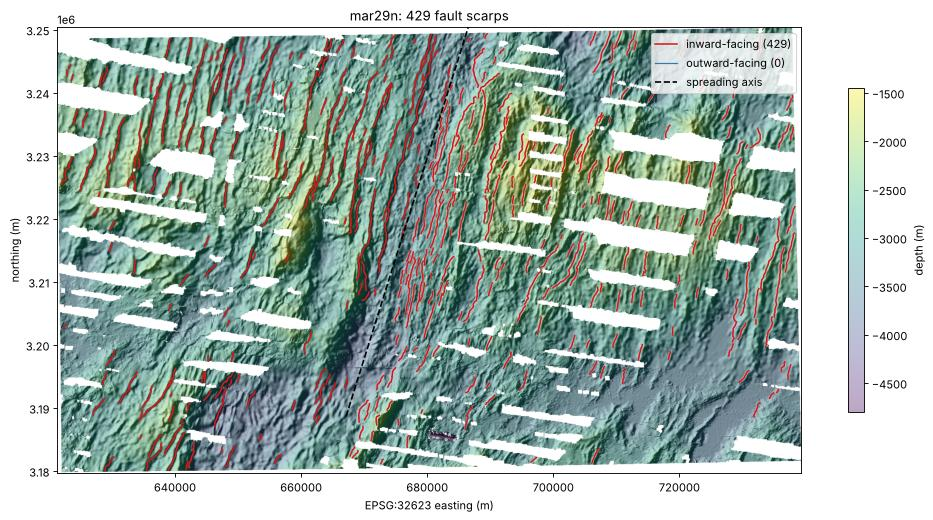

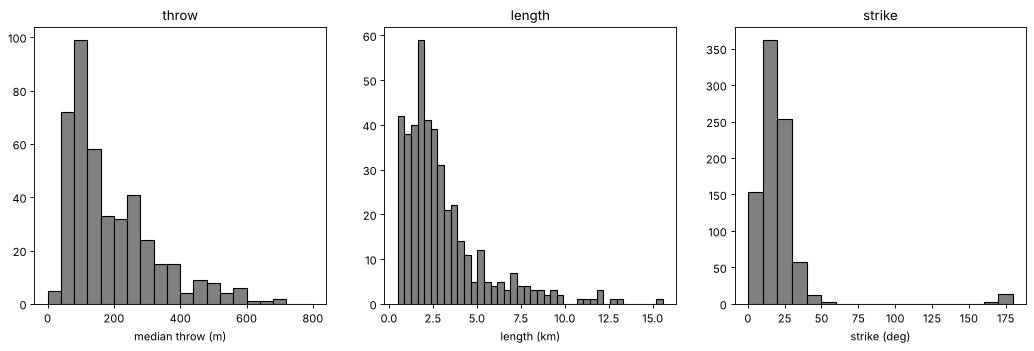

In [19]:
to_lonlat = Transformer.from_crs(f"EPSG:{EPSG}", "EPSG:4326", always_xy=True)
FIELDS = ["id", "polarity", "facing_side", "flank", "length_km", "strike_deg", "facing_az", "throw_median_m",
          "throw_p90_m", "scarp_width_median_m", "scarp_slope_median_deg", "dist_axis_km", "straightness",
          "n_segments", "score"]
features_gj = []
for f_ in faults:
    lon_, lat_ = to_lonlat.transform(f_["xy"][:, 0], f_["xy"][:, 1])
    props = {k: (round(float(f_[k]), 4) if isinstance(f_.get(k), (float, np.floating)) else f_.get(k)) for k in FIELDS}
    features_gj.append({"type": "Feature", "properties": props,
                        "geometry": {"type": "LineString",
                                     "coordinates": [[round(float(a_), 6), round(float(b_), 6)] for a_, b_ in zip(lon_, lat_)]}})
with open(os.path.join(OUT_DIR, "faults.geojson"), "w") as fh:
    json.dump({"type": "FeatureCollection", "features": features_gj}, fh)
with open(os.path.join(OUT_DIR, "faults.csv"), "w", newline="") as fh:
    wr = csv.DictWriter(fh, fieldnames=FIELDS)
    wr.writeheader()
    for f_ in faults:
        wr.writerow({k: f_.get(k) for k in FIELDS})
print(f"写出 {OUT_DIR}/faults.geojson 和 faults.csv：{len(faults)} 条断层")

fig, ax = plt.subplots(figsize=(15, 15 * NY / NX * 0.9 + 1.5))
ax.imshow(HILLSHADE, cmap="gray", extent=EXTENT, vmin=0.1, vmax=1.0)
im = ax.imshow(DEM, cmap="viridis", alpha=0.35, extent=EXTENT)
for f_ in faults:
    if f_["polarity"] == "inward":
        ax.plot(f_["xy"][:, 0], f_["xy"][:, 1], color="#d7191c", lw=1.4)
    else:
        ax.plot(f_["xy"][:, 0], f_["xy"][:, 1], color="#2c7bb6", lw=1.1)
ax_s = np.linspace(AXIS_S_MIN, AXIS_S_MAX, 20)
ax.plot(AX_OX + ax_s * AX_SE + (AXIS_A + AXIS_B * ax_s) * AX_NE,
        AX_OY + ax_s * AX_SN + (AXIS_A + AXIS_B * ax_s) * AX_NN, "k--", lw=1.5)
ax.set_xlim(EXTENT[0], EXTENT[1])
ax.set_ylim(EXTENT[2], EXTENT[3])
n_in = sum(f_["polarity"] == "inward" for f_ in faults)
ax.legend(handles=[Line2D([], [], color="#d7191c", lw=1.4, label=f"inward-facing ({n_in})"),
                   Line2D([], [], color="#2c7bb6", lw=1.1, label=f"outward-facing ({len(faults) - n_in})"),
                   Line2D([], [], color="k", ls="--", label="spreading axis")], loc="upper right")
fig.colorbar(im, ax=ax, shrink=0.55, label="depth (m)")
ax.set_title(f"{AOI_NAME}: {len(faults)} fault scarps")
ax.set_xlabel(f"EPSG:{EPSG} easting (m)")
ax.set_ylabel("northing (m)")
plt.show()

fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))
axs[0].hist([f_["throw_median_m"] for f_ in faults], bins=np.arange(0, 801, 40), color="0.5", edgecolor="k")
axs[0].set_xlabel("median throw (m)")
axs[0].set_title("throw")
axs[1].hist([f_["length_km"] for f_ in faults], bins=40, color="0.5", edgecolor="k")
axs[1].set_xlabel("length (km)")
axs[1].set_title("length")
st_ = np.array([f_["strike_deg"] for f_ in faults])
axs[2].hist(np.concatenate([st_, st_ + 180]) % 180, bins=np.arange(0, 181, 10), color="0.5", edgecolor="k")
axs[2].set_xlabel("strike (deg)")
axs[2].set_title("strike")
plt.show()